# 4. Classification vs. Einstein time

In [ ]:
# --- Google Colab setup (does nothing when run locally) ---
import os, sys, subprocess

REPO_URL = "https://github.com/USERNAME/microlensing-dtw.git"  # <- edit to your repo
USE_DRIVE = True  # keep the repo (and results/, figures/) in Google Drive so they survive between notebooks

if "google.colab" in sys.modules:
    if USE_DRIVE:
        from google.colab import drive
        drive.mount("/content/drive")
        REPO_DIR = "/content/drive/MyDrive/microlensing-dtw"
    else:
        REPO_DIR = "/content/microlensing-dtw"
    # Clone only if the project isn't there yet (you can also upload the folder to Drive by hand)
    if not os.path.isdir(os.path.join(REPO_DIR, "mldtw")):
        subprocess.run(["git", "clone", "-q", REPO_URL, REPO_DIR], check=True)
    # numpy, matplotlib, scikit-learn, joblib are preinstalled on Colab
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "tslearn", "VBMicrolensing"], check=True)
    os.chdir(os.path.join(REPO_DIR, "notebooks"))

os.makedirs("../results", exist_ok=True)
os.makedirs("../figures", exist_ok=True)
print("Working directory:", os.getcwd())

# Notebook 04 only reads the outputs of notebooks 02 and 03
for f in ["../results/accuracy.json", "../results/tE_rmse.json"]:
    if not os.path.exists(f):
        raise FileNotFoundError(f"{f} is missing: run 02_classification and 03_tE first (with USE_DRIVE = True on Colab)")

In [1]:
import sys
sys.path.insert(0, "..")
import json
import numpy as np
import matplotlib.pyplot as plt

In [2]:
acc = json.load(open("../results/accuracy.json"))
rmse = json.load(open("../results/tE_rmse.json"))
soft = [n for n in acc if "soft" in n]
hard = [n for n in acc if "soft" not in n]

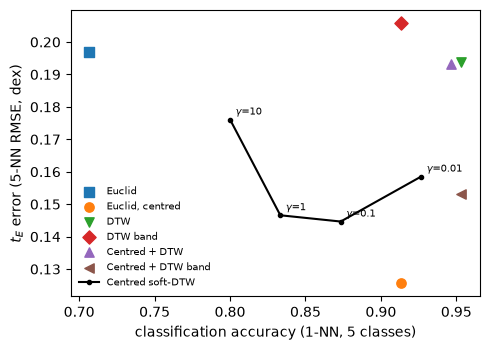

In [3]:
fig, ax = plt.subplots(figsize=(5, 3.6))
for n, m in zip(hard, "sovD^<"):
    ax.scatter(acc[n], rmse[n], marker=m, s=45, zorder=3, label=n)
ax.plot([acc[n] for n in soft], [rmse[n] for n in soft], "k.-", zorder=2, label="Centred soft-DTW")
for n in soft:
    ax.annotate(f"$\\gamma$={n.split('=')[1]}", (acc[n], rmse[n]), xytext=(4, 3), textcoords="offset points", fontsize=7)
ax.set_xlabel("classification accuracy (1-NN, 5 classes)")
ax.set_ylabel("$t_E$ error (5-NN RMSE, dex)")
ax.legend(fontsize=7, frameon=False)
plt.tight_layout()
plt.savefig("../figures/tradeoff.png", dpi=200)
plt.savefig("../figures/tradeoff.pdf")